In [1]:
import numpy as np

#PLAYER 1
His transition matrix

In [2]:
#Transition matrix of the player 1
Player1_Transition_Matrix = {
    "Rock":{"Rock":0.1,"Paper":0.6,"Scissors":0.3},
    "Paper": {"Rock":0.3,"Paper":0.1,"Scissors":0.6},
    "Scissors": {"Rock":0.6,"Paper":0.3,"Scissors":0.1}
}

#PLAYER 2
His learning and transition matrix

In [3]:
# Wiedza gracza drugiego
# Ma słownik wypełniony ilością pojawiania się danych wyborów wykonywanych przez gracza 1

moves = ["Rock", "Paper", "Scissors"]
transition_counts = {
    m1: {m2: 1 for m2 in moves} for m1 in moves
}

# {
#     'Rock': {'Rock': 1, 'Paper': 1, 'Scissors': 1},
#     'Paper': {'Rock': 1, 'Paper': 1, 'Scissors': 1},
#     'Scissors': {'Rock': 1, 'Paper': 1, 'Scissors': 1}
# }

In [4]:
def bayes_theorem(current_move):
    # Oblicza P(następny ruch | obecny ruch) używając twierdzenia Bayesa

    # P(A) - prawdopodobieństwo każdego następnego ruchu
    total_obs = sum(transition_counts[m1][m2] for m1 in moves for m2 in moves)

    p_rock = sum(transition_counts[m1]['Rock'] for m1 in moves) / total_obs
    p_paper = sum(transition_counts[m1]['Paper'] for m1 in moves) / total_obs
    p_scissors = sum(transition_counts[m1]['Scissors'] for m1 in moves) / total_obs

    # P(B|A) - prawdopodobieństwo, że obecny ruch to current_move, jeśli następny ruch to dany move
    total_rock_as_next = sum(transition_counts[m1]['Rock'] for m1 in moves)
    total_paper_as_next = sum(transition_counts[m1]['Paper'] for m1 in moves)
    total_scissors_as_next = sum(transition_counts[m1]['Scissors'] for m1 in moves)

    p_current_given_rock = transition_counts[current_move]['Rock'] / total_rock_as_next
    p_current_given_paper = transition_counts[current_move]['Paper'] / total_paper_as_next
    p_current_given_scissors = transition_counts[current_move]['Scissors'] / total_scissors_as_next

    # P(B) - prawdopodobieństwo całkowite obecnego ruchu
    p_current = (
        p_current_given_rock * p_rock +
        p_current_given_paper * p_paper +
        p_current_given_scissors * p_scissors
    )

    # P(A|B) - prawdopodobieństwo a posteriori (obliczone)
    p_rock_given_current = (p_current_given_rock * p_rock) / p_current
    p_paper_given_current = (p_current_given_paper * p_paper) / p_current
    p_scissors_given_current = (p_current_given_scissors * p_scissors) / p_current

    # Zwracamy prawdopodobieństwo wystąpienia każdej z opcji
    return {
        'Rock': p_rock_given_current,
        'Paper': p_paper_given_current,
        'Scissors': p_scissors_given_current
    }

In [5]:
# Przewidzenie następnego ruchu gracza 1 na podstawie jego obecnego wybranego ruchu
def predict(current_move):
    if current_move is None:
        return np.random.choice(moves)

    probabilities = bayes_theorem(current_move)
    return max(probabilities.items(), key=lambda x: x[1])[0]

In [6]:
#Initial choice for players
Initial_Choice_Distribution = {
    "Rock":1/3,
    "Paper":1/3,
    "Scissors":1/3
}

In [7]:
# Funkcja pomocnicza
def sample_from_dict(prob_dict):
    outcomes = list(prob_dict.keys())
    probabilities = list(prob_dict.values())
    return np.random.choice(outcomes, p=probabilities)

In [8]:
# Gameplay
# Initial choices
player1_choice = sample_from_dict(Initial_Choice_Distribution)
player2_choice = sample_from_dict(Initial_Choice_Distribution)
player1_previous_move = player1_choice

# Stats
player1_wins = 0
player2_wins = 0
ties = 0
skumulowany_wynik = 0
historia_skumulowanych = []


# 1000 Rounds
for round in range(10000):

  # Who wins
  if player1_choice == player2_choice:
        ties += 1
        wynik_rundy = 0
  elif (player1_choice == "Rock" and player2_choice == "Scissors") or (player1_choice == "Scissors" and player2_choice == "Paper") or (player1_choice == "Paper" and player2_choice == "Rock"):
      player1_wins += 1
      wynik_rundy = 1
  else:
      player2_wins += 1
      wynik_rundy = -1

  skumulowany_wynik += wynik_rundy
  historia_skumulowanych.append(skumulowany_wynik)

  # Nowe ruchy
  player1_choice = sample_from_dict(Player1_Transition_Matrix[player1_choice])

  # Przewidywanie z bayesem
  przewidywany = predict(player1_previous_move)
  if przewidywany == "Rock":
    player2_choice = "Paper"
  elif przewidywany == "Paper":
    player2_choice = "Scissors"
  elif przewidywany == "Scissors":
    player2_choice = "Rock"

  # Aktualizacja liczników
  if player1_previous_move is not None:
      transition_counts[player1_previous_move][player1_choice] += 1

  player1_previous_move = player1_choice

#Show results
print("Wyniki końcowe:")
print(f"Player 1 wygrał: {player1_wins}")
print(f"Player 2 wygrał: {player2_wins}")
print(f"Remisy: {ties}")
print(f"Końcowy wynik skumulowany: {skumulowany_wynik}")

print("\n" + "="*60)

print("\nPrawdziwa macierz gracza 1:")
for state in Player1_Transition_Matrix:
    print(f"  Z {state}: {Player1_Transition_Matrix[state]}")

print("\n" + "="*60)

print("\nWyuczone prawdopodobieństwa (po odjęciu 1 zainicjalizowanego przy tworzeniu):")
for poprzedni in moves:
    print(f"\nPo ruchu {poprzedni}:")
    total = sum(transition_counts[poprzedni].values()) - 3  # odejmujemy prior
    for nastepny in moves:
        # odejmujemy 1 (prior) od licznika
        prob = (transition_counts[poprzedni][nastepny] - 1) / total
        print(f"  {nastepny}: {prob}")

Wyniki końcowe:
Player 1 wygrał: 971
Player 2 wygrał: 5881
Remisy: 3148
Końcowy wynik skumulowany: -4910


Prawdziwa macierz gracza 1:
  Z Rock: {'Rock': 0.1, 'Paper': 0.6, 'Scissors': 0.3}
  Z Paper: {'Rock': 0.3, 'Paper': 0.1, 'Scissors': 0.6}
  Z Scissors: {'Rock': 0.6, 'Paper': 0.3, 'Scissors': 0.1}


Wyuczone prawdopodobieństwa (po odjęciu 1 zainicjalizowanego przy tworzeniu):

Po ruchu Rock:
  Rock: 0.10032650638171564
  Paper: 0.5877114870881567
  Scissors: 0.3119620065301276

Po ruchu Paper:
  Rock: 0.32274652147610405
  Paper: 0.09013914095583787
  Scissors: 0.5871143375680581

Po ruchu Scissors:
  Rock: 0.5903759398496241
  Paper: 0.30917293233082704
  Scissors: 0.10045112781954887


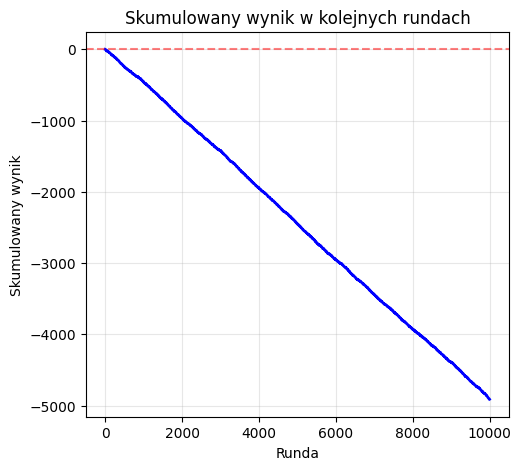

In [9]:
# Wykres
import matplotlib.pyplot as plt
from collections import defaultdict
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(historia_skumulowanych, linewidth=2, color='blue')
plt.xlabel('Runda')
plt.ylabel('Skumulowany wynik')
plt.title('Skumulowany wynik w kolejnych rundach')
plt.grid(True, alpha=0.3)
plt.axhline(y=0, color='r', linestyle='--', alpha=0.5)